In [20]:
# Import analysis libraries.
import pandas as pd
import numpy as np
import scipy.stats as st

# Import visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Import engine connection file.
from _01_database_connection import engine

In [41]:
# Read the data from the database.
fact_sales = pd.read_sql(
    sql="SELECT sales, order_number FROM gold.fact_sales",
    con=engine
)

### GRAIN: Each row represents an item within an order. ###

**Q1: What is the distribution of the revenue by the item-level?**

In [44]:
item_revenue = fact_sales["sales"]
item_revenue_range = item_revenue.max() - item_revenue.min()

kur_item = st.kurtosis(item_revenue, fisher=True)

ske_item = st.skew(item_revenue)

# Calculate standard deviation, mean and median for the item_revenue.
item_revenue_std = item_revenue.std(ddof=0) 
item_revenue_mean = item_revenue.mean()
item_revenue_median = item_revenue.median()

# Calculate coefficient of variation(CV).
item_revenue_cv = (item_revenue_std / item_revenue_mean) * 100 

# Show the results.
print(f"""
Range of revenue: {item_revenue_range}
Kurtosis of revenue: {kur_item}
Skewness of revenue: {ske_item}
Standard deviation of revenue: {item_revenue_std}
Mean of revenue: {item_revenue_mean}
Median of revenue: {item_revenue_median}
Coefficient of variation of revenue: {item_revenue_cv}
""")


Range of revenue: 3576
Kurtosis of revenue: 2.5179181043671743
Skewness of revenue: 1.928453935881108
Standard deviation of revenue: 927.5748818224988
Mean of revenue: 485.4403649973503
Median of revenue: 30.0
Coefficient of variation of revenue: 191.07905907815513



## Item-level Revenue Distribution Summary

- **Mean (485) >> Median (30) and Skewness = 1.93** -> strongly right-skewed; a few large item values inflate the average.
- **Excess kurtosis = 2.52** -> heavy tails, more extreme values than a normal distribution.
- **CV = 191%** -> very high variability relative to the mean.

**Decision:** reporting the median as the typical item value and apply a log transform before modeling.

In [40]:
# Inspect the percentiles.

P5, Q1, Q2, Q3, P95 = item_revenue.quantile([0.05, 0.25, 0.5, 0.75, 0.95])

# Interquartile range.
IQR = Q3 - Q1

# Upper bound.
item_revenue_upper_bound = Q3 + 1.5 * IQR

# Lower bound.
item_revenue_lower_bound = Q1 - 1.5 * IQR

# Any value greater then upper bound or less than lower bound is outlier.
outliers = item_revenue[(item_revenue > item_revenue_upper_bound) | (item_revenue < item_revenue_lower_bound)]
outliers_percent = len(outliers) / len(item_revenue) * 100

print(f"""
IQR: {IQR}
P5: {P5}
Q1: {Q1}
Q2 (median): {Q2}
Q3: {Q3}
P95: {P95}
outliers_percent: {outliers_percent:.2f}%
""")


IQR: 532.0
P5: 2.0
Q1: 8.0
Q2 (median): 30.0
Q3: 540.0
P95: 2443.0
outliers_percent: 15.86%



## Quantile Analysis

| Metric | Value |
|---|---|
| P5 | 2 |
| Q1 | 8 |
| Median | 30 |
| Q3 | 540 |
| P95 | 2,443 |
| IQR | 532 |

- Half of all items revenue fall between 8 and 540, a very wide spread.
- The jump from the median (30) to Q3 (540) shows a strongly right-skewed distribution.

**Decision:** Using median/IQR instead of mean/std when summarizing revenue.

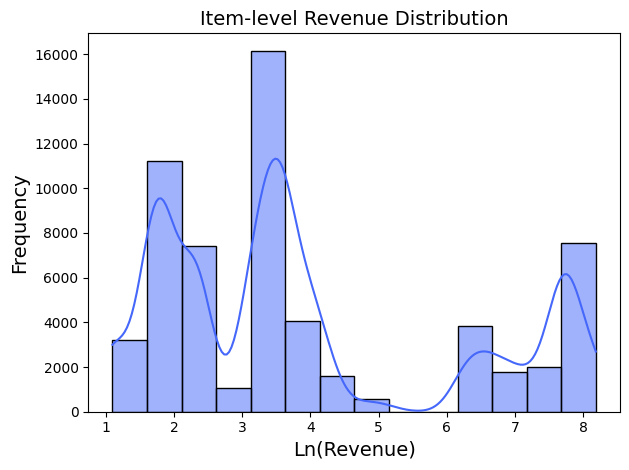

In [45]:
# Apply natural logarithm transformation to reduce the right-skewness and improve visualization.
trans_item_revenue = np.log1p(item_revenue) # e number is the base.

# Plot histogram to visualize the distribution of the item_revenue.
sns.histplot(
    data=trans_item_revenue,
    color="#4567FA",
    edgecolor="black",
    binwidth=0.5,
    kde=True,
    element="bars"
    );

# Add labels.
plt.title("Item-level Revenue Distribution", fontsize=14);
plt.xlabel("Ln(Revenue)", fontsize=14);
plt.ylabel("Frequency", fontsize=14);

plt.tight_layout();

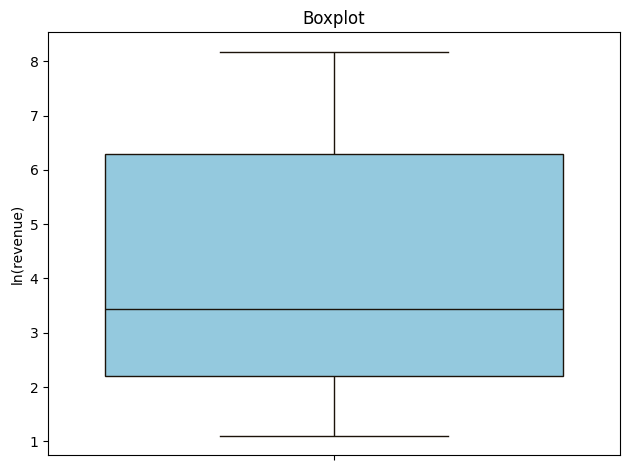

In [46]:
# Plot boxblot to visual the skewness.
sns.boxplot(
    data=trans_item_revenue,
    color="#87CEEB",
    linecolor="#1B130A"
    );

plt.title("Boxplot");
plt.ylabel("ln(revenue)");
plt.tight_layout();
# The distribution shows potential right-skewness with greate dispersion above the median.

##### Conclusion:
***Item-level revenue is highly right-skewed, with substantial dispersion and potential high-value outliers. The median ($30) is considerably lower than the mean ($485), indicating that a small number of high-revenue items may significantly influence the average. Log transformation was applied to reduces skewness and improves visualization of the distribution.***

**Q2: What is the distribution of the revenue by the order-level?**

In [47]:
# Group the data by the order_number to aggregate it by the order-level.
grouped_orders = fact_sales.groupby(
    by="order_number"
)["sales"].sum()

# Pick a sample.
grouped_orders.sample(5)

order_number
SO52082      70
SO64150      95
SO69732     784
SO66820    2320
SO70431    2428
Name: sales, dtype: int64

In [65]:
# Order revenue series.
order_revenue = grouped_orders

# Number of orders.
total_orders = order_revenue.count() 

# Calculate the range.
order_revenue_range = order_revenue.max() - order_revenue.min() 

kur_order = st.kurtosis(order_revenue, fisher=True)
ske_order = st.skew(order_revenue) 

# Calculate standard deviation, mean and median for the order_revenue.
order_revenue_mean = order_revenue.mean()

order_revenue_median = order_revenue.median()

order_revenue_std = order_revenue.std(ddof=0)

# Calculate coefficient of variation(CV).
order_revenue_cv = (order_revenue_std / order_revenue_mean) * 100

print(f"""
Total Orders: {total_orders}
Range: {order_revenue_range}
Kurtosis: {kur_order}
Skewness: {ske_order}
Mean: {order_revenue_mean}
Median: {order_revenue_median}
Standard deviation: {order_revenue_std}
Coefficient of variation: {order_revenue_cv}
""")


Total Orders: 27645
Range: 3576
Kurtosis: -0.8159735237758872
Skewness: 0.7318035514200157
Mean: 1060.330294809188
Median: 594.0
Standard deviation: 1148.1363008270555
Coefficient of variation: 108.28100512149081



### Interpretation

- **Right-skewed (0.73):** Most orders are small; a few large ones pull the tail right.
- **Mean > Median (1,060 vs 594):** Confirms the skew; the median better reflects a typical order.
- **Kurtosis -0.82:** Flatter than normal, with light tails and few extreme outliers.
- **CV 108%:** Very high variability; the std dev exceeds the mean.

**Takeaway:** Revenue is asymmetric and highly dispersed.

In [61]:
# Inspect the percentiles.

P5, Q1, Q2, Q3, P95 = order_revenue.quantile([0.05, 0.25, 0.5, 0.75, 0.95])

IQR = Q3 - Q1

# Upper bound.
order_revenue_upper_bound = Q3 + 1.5 * IQR

# Lower bound.
order_revenue_lower_bound = Q1 - 1.5 * IQR

outliers = order_revenue[(order_revenue > order_revenue_upper_bound) | (order_revenue < order_revenue_lower_bound)]
outliers_percent = len(outliers) / len(order_revenue) * 100

print(f"""
IQR: {IQR}
P5: {P5}
Q1: {Q1}
Q2 (median): {Q2}
Q3: {Q3}
P95: {P95}
outliers_percent: {outliers_percent:.2f}
""")


IQR: 2136.0
P5: 8.0
Q1: 46.0
Q2 (median): 594.0
Q3: 2182.0
P95: 3578.0
outliers_percent: 0.00



### Interpretation

- **Heavy lower concentration:** 25% of orders are 46 or less, and the median is only 594.
- **Wide middle spread:** The IQR is 2,136, so the middle 50% of orders vary a lot.
- **Long upper range:** Q3 is 2,182 and P95 is 3,578, so the top orders are many times larger than a typical one.
- **Right skew confirmed:** The gap from Q2 to Q3 (1,588) is far larger than from Q1 to Q2 (548).

**Takeaway:** Order values are widely spread with moderate right skew and no statistical outliers.
**No outliers:** Upper bound > max value, so 0% of orders are flagged.

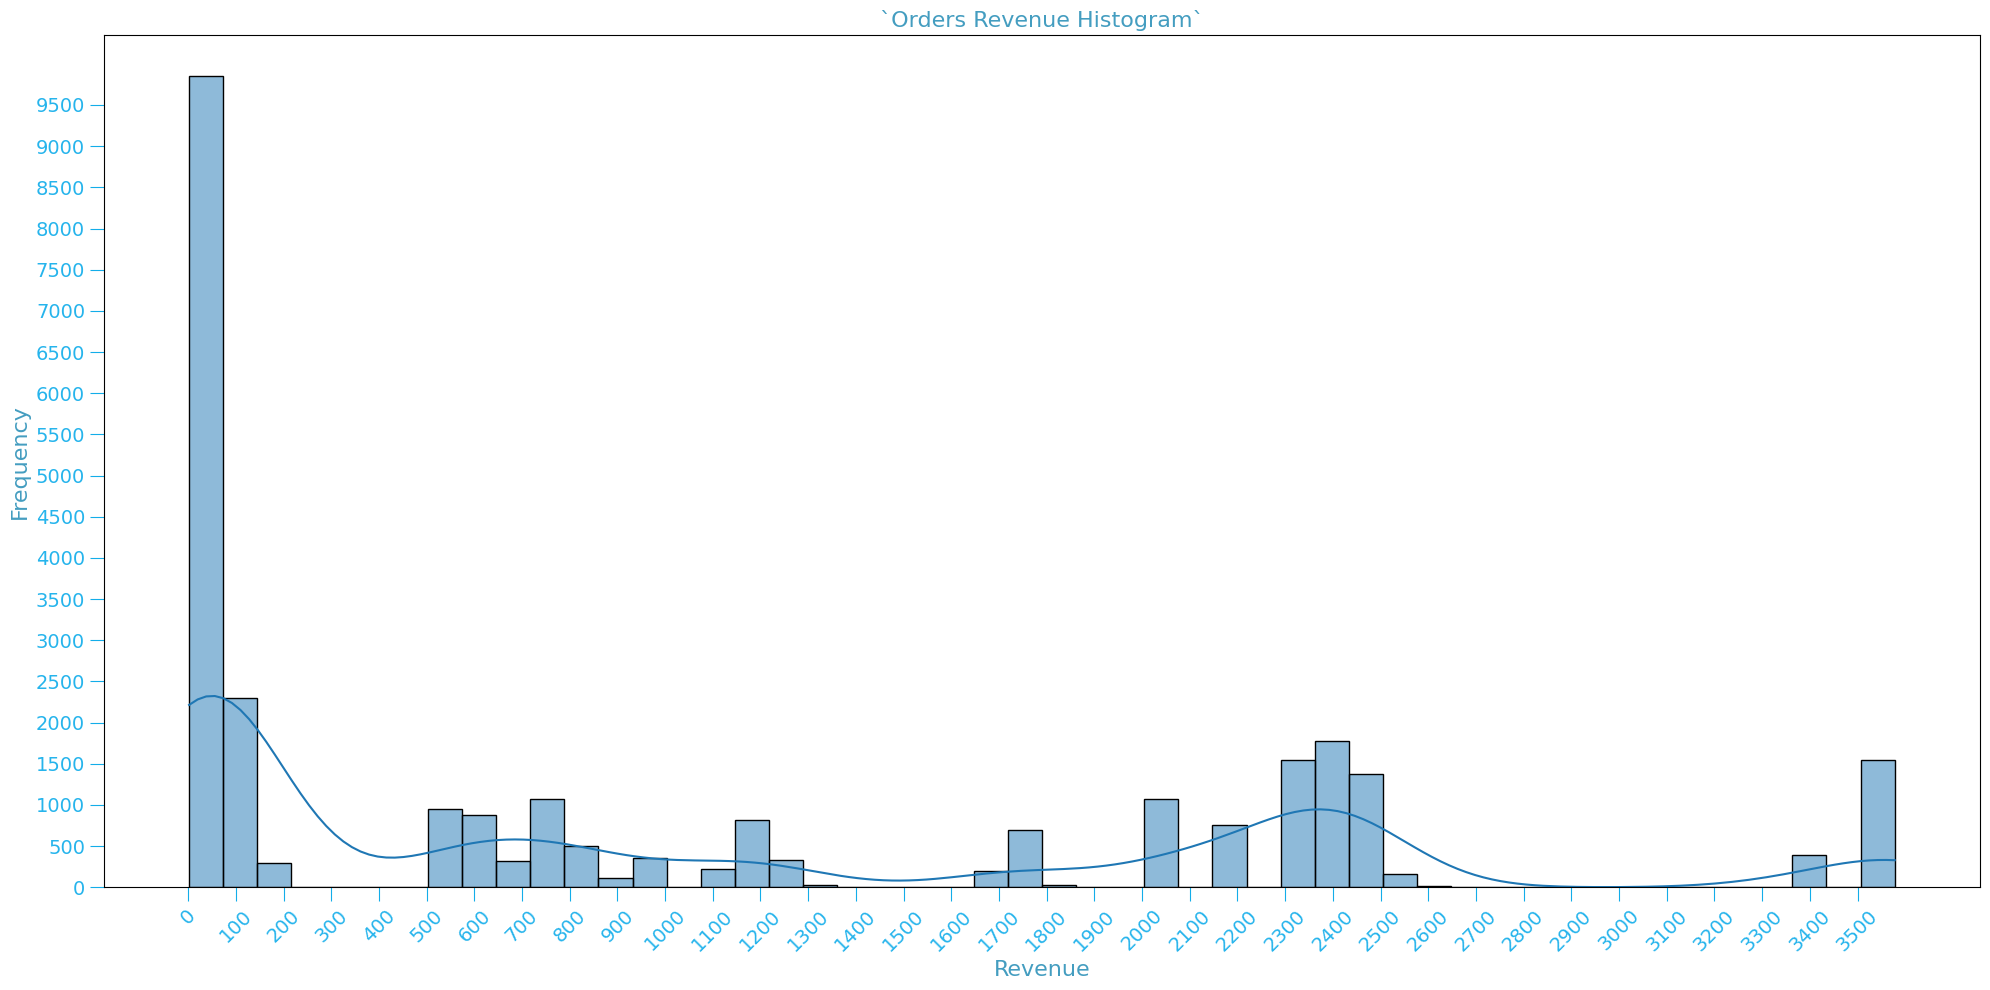

In [70]:
# Make an object to plot on.
fig, ax = plt.subplots(figsize=(20, 10))

# Plot a histogram.
sns.histplot(
    data=order_revenue,
    bins=50,
    kde=True,
    ax=ax
);

# Add titles to the plot and the label.
ax.set_title("`Orders Revenue Histogram`", fontsize=16, color="#449DC0");
ax.set_xlabel("Revenue", fontsize=16, color="#449DC0");
ax.set_ylabel("Frequency", fontsize=16, color="#449DC0");


# Add some labels settings.
ax.set_xticks(np.arange(0, order_revenue.max(), 100));
ax.set_yticks(np.arange(0, 10000, 500));
ax.tick_params("x", rotation=45, labelsize=14, length=10, color="#13ADE9", labelcolor="#26B4EC");
ax.tick_params("y", labelsize=14, length=10, color="#13ADE9", labelcolor="#26B4EC");
plt.tight_layout();

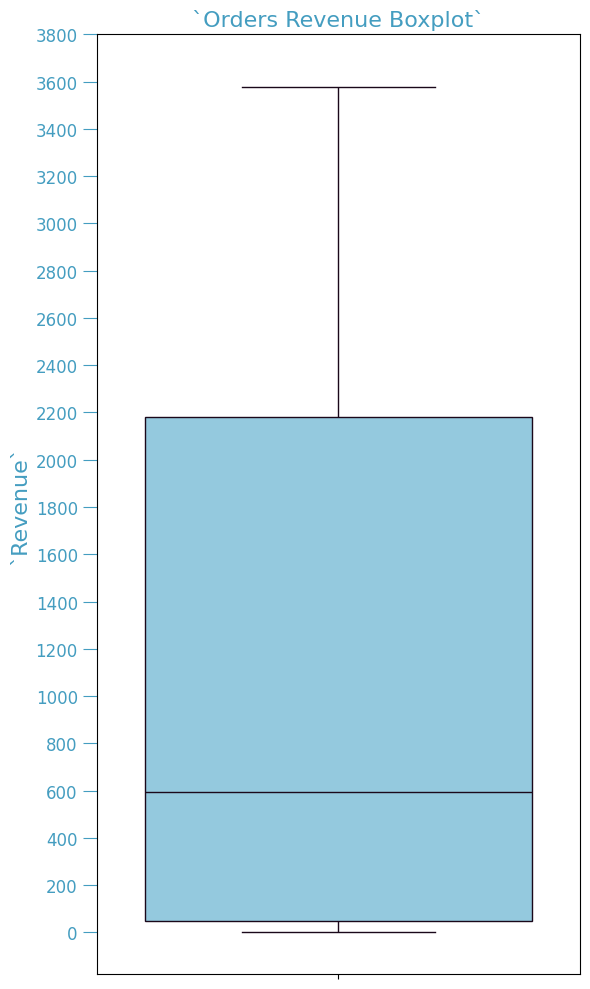

In [30]:
# Make an object.
fig, ax = plt.subplots(figsize=(6, 10))

# Plot a boxplot.
sns.boxplot(
    data=order_revenue,
    color='#87CEEB',
    linecolor="#1A081A",
    vert=True,
    ax=ax
);

# Set the labels.
ax.set_title("`Orders Revenue Boxplot`", fontsize=16, color="#449DC0");
ax.set_ylabel("`Revenue`", fontsize=16, color="#449DC0")
ax.set_yticks(np.arange(0, 4000, 200));
ax.tick_params("y", length=10, color="#449DC0", labelsize=12, labelcolor="#449DC0")

plt.tight_layout();